In [ ]:


import pandas as pd

# Load the dataset
df = pd.read_csv("sample_loan_applicants.csv")

# Display first five rows
print(df.head())

# Check dataset size
print("Dataset shape:", df.shape)

# Check column information
print(df.info())

# Check missing values
print(df.isnull().sum())


In [11]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("default", axis=1)
y = df["default"]

# First split: 80% training + validation, 20% testing
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 75% training, 25% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.25,
    random_state=42,
    stratify=y_trainval
)

# Display dataset sizes
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))


Training rows: 840
Validation rows: 280
Testing rows: 280


In [12]:

print("Original default percentage:", y.mean())

print("Training default percentage:", y_train.mean())

print("Validation default percentage:", y_val.mean())

print("Testing default percentage:", y_test.mean())


Original default percentage: 0.2792857142857143
Training default percentage: 0.27976190476190477
Validation default percentage: 0.2785714285714286
Testing default percentage: 0.2785714285714286


Depth: 1 | Train: 0.720 | Validation: 0.721
Depth: 3 | Train: 0.733 | Validation: 0.750
Depth: 5 | Train: 0.774 | Validation: 0.757
Depth: 10 | Train: 0.892 | Validation: 0.643
Depth: None | Train: 1.000 | Validation: 0.650


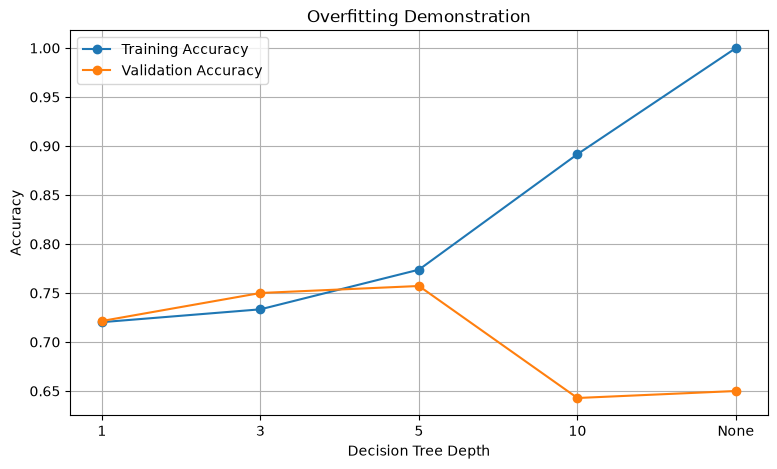

In [13]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Use numeric features for this experiment
features = [
    "age",
    "annual_income",
    "credit_score",
    "debt_to_income",
    "loan_amount"
]

depths = [1, 3, 5, 10, None]

train_scores = []
val_scores = []

for depth in depths:

    # Create decision tree
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Train the model
    model.fit(X_train[features], y_train)

    # Predict training and validation data
    train_pred = model.predict(X_train[features])
    val_pred = model.predict(X_val[features])

    # Calculate accuracy
    train_accuracy = accuracy_score(y_train, train_pred)
    val_accuracy = accuracy_score(y_val, val_pred)

    train_scores.append(train_accuracy)
    val_scores.append(val_accuracy)

    print(
        f"Depth: {depth} | "
        f"Train: {train_accuracy:.3f} | "
        f"Validation: {val_accuracy:.3f}"
    )

# Plot results
plt.figure(figsize=(9, 5))

labels = [str(d) for d in depths]

plt.plot(labels, train_scores, marker="o",
         label="Training Accuracy")

plt.plot(labels, val_scores, marker="o",
         label="Validation Accuracy")

plt.xlabel("Decision Tree Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Demonstration")
plt.legend()
plt.grid()
plt.show()


5-fold cross-validation

In [14]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "age",
    "annual_income",
    "employment_years",
    "credit_score",
    "debt_to_income",
    "loan_amount"
]

cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    cv_pipeline,
    X_train[numeric_features],
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Fold scores:", scores)
print(f"Mean accuracy: {scores.mean():.3f}")
print(f"Standard deviation: {scores.std():.3f}")

Fold scores: [0.7202381  0.75       0.69047619 0.74404762 0.70238095]
Mean accuracy: 0.721
Standard deviation: 0.023


data leakage :Incorrect approach — fit the scaler before splitting:

In [15]:
from sklearn.preprocessing import StandardScaler

numeric_features = [
    "age", "annual_income", "employment_years",
    "credit_score", "debt_to_income", "loan_amount"
]

# INCORRECT: learns statistics from all rows
leaky_scaler = StandardScaler()
X_scaled_leaky = leaky_scaler.fit_transform(
    X[numeric_features]
)

Correct approach — fit only on training data:

In [16]:
# CORRECT: learn statistics from training data only
correct_scaler = StandardScaler()

X_train_scaled = correct_scaler.fit_transform(
    X_train[numeric_features]
)

# Only transform validation and test data
X_val_scaled = correct_scaler.transform(
    X_val[numeric_features]
)

X_test_scaled = correct_scaler.transform(
    X_test[numeric_features]
)

print("Training scaler means:")
print(correct_scaler.mean_)

Training scaler means:
[3.87500000e+01 5.66985869e+04 6.59654762e+00 6.83713095e+02
 2.43939286e-01 8.12538619e+04]


1. Data leakage occurs when information from validation or test data influences model training.



2. Scaling the entire dataset before splitting causes leakage because the scaler learns statistics from all rows.



3. The correct method is to fit the scaler only on the training data.



4. Then use that fitted scaler to transform validation and test data.

Classify the four problems

1. spam detection:
    * supervised learning.
    * emails have labeles like spam and not spam.

2. Customer segmentation.
    * Unsupervised learning
    * Groups customers by similarities

3. House price prediction
    * supervised learning
    * Learns from known house prices  

4. Anomaly detection
    * Unsupervised learning
    * Finds unusual patterns without labels


 Machine Learning workflow. 
 1. data collection for the project:
    collecting the datasets from known sources

 2. Data prepration:
    the data may contain missing, duplicate values, improper values, duplicate columns.
    so data cleaning and preprocessing is necessry to train the model.

 3. Model selection:
    based on data we need to classify the data to be supervised or unsupervused then 
    selecting the algorithms to train

 4. Model training:
    training the model by spliting data with algorithms.

 5. Model evaluation:
    after training, evaluate accuray to get proper predictions.

 6. Model improvement:
    if accuracy is not good in a algorithm, again train the model with other algorithms.

 7. Prediction and Deploy
    After getting exact predictions deploy it.            


Task 2: Preprocessing, Features and Pipeline

Handling missing values (Imputation)

In [17]:
# Check missing values in each column
print(X_train.isnull().sum())

age                 0
annual_income       0
employment_years    0
credit_score        0
debt_to_income      0
loan_amount         0
education           0
employment_type     0
marital_status      0
loan_purpose        0
application_date    0
dtype: int64


Apply SimpleImpute

In [18]:
from sklearn.impute import SimpleImputer

numeric_features = [
    "age",
    "annual_income",
    "employment_years",
    "credit_score",
    "debt_to_income",
    "loan_amount"
]

categorical_features = [
    "education",
    "employment_type",
    "marital_status",
    "loan_purpose"
]

# Numeric: fill missing values with median
numeric_imputer = SimpleImputer(strategy="median")

X_train_numeric = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

# Categorical: fill missing values with most frequent value
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_categorical = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

print("Numeric data shape:", X_train_numeric.shape)
print("Categorical data shape:", X_train_categorical.shape)

Numeric data shape: (840, 6)
Categorical data shape: (840, 4)


Try KNNImputer

In [19]:
from sklearn.impute import KNNImputer

knn_imputer = KNNImputer(n_neighbors=5)

X_train_knn = knn_imputer.fit_transform(
    X_train[numeric_features]
)

print("KNN imputed data shape:", X_train_knn.shape)

KNN imputed data shape: (840, 6)


Encoding categorical columns

OneHotEncoder,ordinal encoder

In [20]:
#First, inspect the actual education categories in your dataset. Run:


print("Education categories:")
print(sorted(df["education"].dropna().unique()))

print("\nOther categorical categories:")
for col in ["employment_type", "marital_status", "loan_purpose"]:
    print(col, sorted(df[col].dropna().unique()))

Education categories:
['Bachelor', 'Doctorate', 'High School', 'Master']

Other categorical categories:
employment_type ['Contract', 'Salaried', 'Self-employed', 'Unemployed']
marital_status ['Divorced', 'Married', 'Single']
loan_purpose ['Auto', 'Business', 'Education', 'Home', 'Medical', 'Personal']


Next, we'll encode the columns. For now, use this code after checking your education values:

In [23]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Replace this list with the actual education order
education_order = [
    "High School",
    "Bachelor",
    "Master",
    "Doctorate"
]

# Encode categories without a natural order
onehot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_categories = onehot_encoder.fit_transform(
    X_train[["employment_type", "marital_status", "loan_purpose"]]
)

print("One-hot encoded shape:", encoded_categories.shape)

# Encode education in its natural order
ordinal_encoder = OrdinalEncoder(
    categories=[education_order]
)

encoded_education = ordinal_encoder.fit_transform(
    X_train[["education"]]
)

print("Ordinal encoded shape:", encoded_education.shape)

One-hot encoded shape: (840, 13)
Ordinal encoded shape: (840, 1)


Feature Engineering

Extract information from dates

In [27]:
df["application_date"] = pd.to_datetime(
    df["application_date"]
)

df["application_month"] = (
    df["application_date"].dt.month
)

df["application_year"] = (
    df["application_date"].dt.year
)

print(df[[
    "application_date",
    "application_month",
    "application_year"
]].head())

  application_date  application_month  application_year
0       2023-12-07                 12              2023
1       2024-09-22                  9              2024
2       2025-12-08                 12              2025
3       2025-03-08                  3              2025
4       2022-01-12                  1              2022


In [ ]:
Create an interaction feature

In [ ]:
df["loan_to_income_ratio"] = (
    df["loan_amount"] / df["annual_income"]
)

print(df[[
    "annual_income",
    "loan_amount",
    "loan_to_income_ratio"
]].head())

Apply a logarithmic transformation

In [ ]:
import numpy as np

df["log_income"] = np.log1p(
    df["annual_income"]
)

print(df[[
    "annual_income",
    "log_income"
]].head())

build the preprocessing pipeline

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)
from sklearn.linear_model import LogisticRegression

# Numeric columns
numeric_features = [
    "age",
    "annual_income",
    "employment_years",
    "credit_score",
    "debt_to_income",
    "loan_amount"
]

# Nominal categorical columns
categorical_features = [
    "employment_type",
    "marital_status",
    "loan_purpose"
]

# Ordered categorical column
ordinal_features = ["education"]

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Nominal categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Education preprocessing
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[[
            "High School",
            "Bachelor",
            "Master",
            "Doctorate"
        ]]
    ))
])

# Combine all preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("ord", ordinal_pipeline, ordinal_features)
])

# Complete machine-learning pipeline
loan_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train using training data only
loan_pipeline.fit(X_train, y_train)

# Evaluate on validation data
validation_accuracy = loan_pipeline.score(X_val, y_val)

print("Validation accuracy:", validation_accuracy)

Validation accuracy: 0.725


Save and Load Your Model Using Joblib

Save the trained pipelin


In [29]:
import joblib

# Save the complete trained pipeline
joblib.dump(
    loan_pipeline,
    "loan_default_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Load the saved model

In [30]:
loaded_model = joblib.load(
    "loan_default_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


Predict using three new raw applications

In [31]:
# Select three raw application rows
new_applicants = X_train.iloc[:3].copy()

# Predict default (0 = no default, 1 = default)
predictions = loaded_model.predict(new_applicants)

# Predict default probabilities
probabilities = loaded_model.predict_proba(new_applicants)

print("Predictions:", predictions)
print("Default probabilities:")
print(probabilities[:, 1])

Predictions: [0 0 0]
Default probabilities:
[0.30485035 0.33692566 0.21009902]


Display the results clearly

In [32]:
results = new_applicants.copy()

results["predicted_default"] = predictions
results["default_probability"] = probabilities[:, 1]

print(results[[
    "age",
    "annual_income",
    "loan_amount",
    "predicted_default",
    "default_probability"
]])

      age  annual_income  loan_amount  predicted_default  default_probability
200    43        50193.0      69689.0                  0             0.304850
1245   40        47807.0      76838.0                  0             0.336926
1355   44        29003.0      51497.0                  0             0.210099


Task 3 – Model Training

Logistic Regression training

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


Make predictions

In [34]:
lr_predictions = lr_pipeline.predict(X_val)

print("First 10 predictions:")
print(lr_predictions[:10])

First 10 predictions:
[0 0 0 0 0 0 0 1 0 0]


Check validation accuracy

In [35]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(
    y_val,
    lr_predictions
)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.725


Decision Tree Classifier

Train a Decision Tree

In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

dt_pipeline.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


Make predictions


In [37]:
dt_predictions = dt_pipeline.predict(X_val)

print("First 10 predictions:")
print(dt_predictions[:10])

First 10 predictions:
[0 1 0 0 1 0 1 0 0 0]


Calculate accuracy

In [38]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(
    y_val,
    dt_predictions
)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.75


Compare both models

In [39]:
print("Logistic Regression:", lr_accuracy)
print("Decision Tree:", dt_accuracy)

Logistic Regression: 0.725
Decision Tree: 0.75


Random Forest Classifier

Train Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        oob_score=True,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Make predictions

In [41]:
rf_predictions = rf_pipeline.predict(X_val)

print("First 10 predictions:")
print(rf_predictions[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


Calculate accuracy

In [42]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(
    y_val,
    rf_predictions
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7285714285714285


Check OOB score

In [43]:
rf_model = rf_pipeline.named_steps["classifier"]

print("OOB Score:", rf_model.oob_score_)

OOB Score: 0.7083333333333334


Compare all three models

In [44]:
print("Logistic Regression:", lr_accuracy)
print("Decision Tree:", dt_accuracy)
print("Random Forest:", rf_accuracy)

Logistic Regression: 0.725
Decision Tree: 0.75
Random Forest: 0.7285714285714285


XGBoost Classifier

In [47]:
!pip install xgboost

Prepare the data

In [48]:
from sklearn.base import clone

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

Training shape: (840, 20)
Validation shape: (280, 20)


instal xgboost

In [54]:
pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#Test the installation of xgboost



In [57]:
import xgboost

print("XGBoost version:", xgboost.__version__)

from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost version: 3.4.1
XGBoost imported successfully!


Prepare the training and validation data

In [59]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)

Training data shape: (840, 20)
Validation data shape: (280, 20)


Train XGBoost with early stopping

In [55]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    eval_metric="logloss",
    early_stopping_rounds=20,
    random_state=42
)

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

print("XGBoost training completed!")
print("Best iteration:", xgb_model.best_iteration)

XGBoost training completed!
Best iteration: 55


: Evaluate XGBoost accuracy

In [60]:
from sklearn.metrics import accuracy_score

xgb_predictions = xgb_model.predict(X_val_processed)

xgb_accuracy = accuracy_score(y_val, xgb_predictions)

print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 0.7357142857142858


Compare our four models

In [61]:
print("MODEL COMPARISON")
print("-------------------------")

print("Logistic Regression:", lr_accuracy)
print("Decision Tree:", dt_accuracy)
print("Random Forest:", rf_accuracy)
print("XGBoost:", xgb_accuracy)

MODEL COMPARISON
-------------------------
Logistic Regression: 0.725
Decision Tree: 0.75
Random Forest: 0.7285714285714285
XGBoost: 0.7357142857142858


Predict probabilities with Logistic Regression

In [62]:
# Select five validation applicants
five_applicants = X_val.iloc[:5]

# Predict classes
predicted_classes = lr_pipeline.predict(five_applicants)

# Predict probabilities
predicted_probabilities = lr_pipeline.predict_proba(five_applicants)

print("Predicted Classes:")
print(predicted_classes)

print("\nPredicted Probabilities:")
print(predicted_probabilities)

Predicted Classes:
[0 0 0 0 0]

Predicted Probabilities:
[[0.80908284 0.19091716]
 [0.65358002 0.34641998]
 [0.7870921  0.2129079 ]
 [0.54046413 0.45953587]
 [0.83009227 0.16990773]]


Understand the output
predict() gives a class:
- 0 = No default
- 1 = Default

predict_proba() gives two probabilities for each applicant:
- First column = probability of class 0.
- Second column = probability of class 1.

It means:
- 80% probability of no default.
- 20% probability of default.
The predicted class is 0 because the no-default probability is higher.

run the probability prediction code:

In [63]:
five_applicants = X_val.iloc[:5]

predicted_classes = lr_pipeline.predict(five_applicants)

predicted_probabilities = lr_pipeline.predict_proba(five_applicants)

print("Predicted Classes:")
print(predicted_classes)

print("\nPredicted Probabilities:")
print(predicted_probabilities)

Predicted Classes:
[0 0 0 0 0]

Predicted Probabilities:
[[0.80908284 0.19091716]
 [0.65358002 0.34641998]
 [0.7870921  0.2129079 ]
 [0.54046413 0.45953587]
 [0.83009227 0.16990773]]


To make the output easier to understand, run this additional cell:

In [64]:
import pandas as pd

probability_results = pd.DataFrame({
    "Predicted Class": predicted_classes,
    "Probability_No_Default": predicted_probabilities[:, 0],
    "Probability_Default": predicted_probabilities[:, 1]
})

print(probability_results)

   Predicted Class  Probability_No_Default  Probability_Default
0                0                0.809083             0.190917
1                0                0.653580             0.346420
2                0                0.787092             0.212908
3                0                0.540464             0.459536
4                0                0.830092             0.169908


Feature Importance

In [65]:
import pandas as pd

# Get feature importance from Random Forest
rf_model = rf_pipeline.named_steps["classifier"]

feature_names = (
    rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
)

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Display top 5 features
rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 5 Random Forest Features:")
print(rf_importance.head(5))

Top 5 Random Forest Features:
                 Feature  Importance
3      num__credit_score    0.153803
1     num__annual_income    0.146886
4    num__debt_to_income    0.129735
5       num__loan_amount    0.123367
2  num__employment_years    0.111211


Now calculate XGBoost feature importance

In [66]:
import pandas as pd

# Get XGBoost feature importance
xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Sort from highest to lowest
xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 5 XGBoost Features:")
print(xgb_importance.head(5))

Top 5 XGBoost Features:
                          Feature  Importance
3               num__credit_score    0.086060
7   cat__employment_type_Salaried    0.082743
14     cat__loan_purpose_Business    0.070935
4             num__debt_to_income    0.065402
1              num__annual_income    0.062833


Regression models

1. Linear Regression

2. Ridge Regression

3. Lasso Regression

Prepare regression data

In [67]:
# Define regression target
X_reg = df.drop("loan_amount", axis=1)
y_reg = df["loan_amount"]

# Split into training and validation data
X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Regression training shape:", X_reg_train.shape)
print("Regression validation shape:", X_reg_val.shape)

Regression training shape: (1120, 15)
Regression validation shape: (280, 15)


Step 2: Important preprocessing adjustment

For regression, we must remove loan_amount from the input features. We also need a new preprocessor that handles the remaining columns.

In [68]:
numeric_reg_features = [
    "age", "annual_income", "employment_years",
    "credit_score", "debt_to_income"
]

categorical_reg_features = [
    "employment_type", "marital_status", "loan_purpose"
]

ordinal_reg_features = ["education"]

reg_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_reg_features),
    ("cat", categorical_pipeline, categorical_reg_features),
    ("ord", ordinal_pipeline, ordinal_reg_features)
])

Train regression models

Linear Regression
Linear Regression tries to find a mathematical relationship between input features and the loan amount.

In [69]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_pipeline = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("regressor", LinearRegression())
])

linear_pipeline.fit(X_reg_train, y_reg_train)

linear_predictions = linear_pipeline.predict(X_reg_val)

print("Linear Regression training completed!")
print("First 5 predictions:", linear_predictions[:5])

Linear Regression training completed!
First 5 predictions: [72267.92339781 73855.48266916 83843.04032813 87791.52218122
 78559.38491756]


Ridge Regression
Ridge Regression is similar to Linear Regression, but it adds a penalty to help prevent overly large coefficients.

In [70]:
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_reg_train, y_reg_train)

ridge_predictions = ridge_pipeline.predict(X_reg_val)

print("Ridge Regression training completed!")
print("First 5 predictions:", ridge_predictions[:5])

Ridge Regression training completed!
First 5 predictions: [72284.70093364 73854.92713452 83833.18378594 87789.23472511
 78552.19627618]


Lasso Regression
Lasso Regression also adds a penalty. It can shrink some feature coefficients to exactly zero, effectively removing those features from the model.

In [71]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("regressor", Lasso(alpha=100.0, max_iter=10000))
])

lasso_pipeline.fit(X_reg_train, y_reg_train)

lasso_predictions = lasso_pipeline.predict(X_reg_val)

print("Lasso Regression training completed!")
print("First 5 predictions:", lasso_predictions[:5])

Lasso Regression training completed!
First 5 predictions: [73584.52791765 73491.76340131 83676.3359743  88016.4982577
 77569.52933541]


Compare regression model performance
We'll use three metrics:
- MAE: Average absolute prediction error. Lower is better.
- RMSE: Penalizes larger prediction errors more heavily. Lower is better.
- R²: Measures how much variation the model explains. Closer to 1 is generally better.

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
import numpy as np
import pandas as pd

# Mean baseline: predicts the average training loan amount
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_reg_train, y_reg_train)
baseline_predictions = baseline.predict(X_reg_val)

models = {
    "Mean Baseline": baseline_predictions,
    "Linear Regression": linear_predictions,
    "Ridge Regression": ridge_predictions,
    "Lasso Regression": lasso_predictions
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_reg_val, predictions)),
        "R2": r2_score(y_reg_val, predictions)
    })

regression_results = pd.DataFrame(results)
print(regression_results.round(3))

               Model        MAE       RMSE     R2
0      Mean Baseline  17713.689  22240.529 -0.002
1  Linear Regression  14653.747  18403.178  0.314
2   Ridge Regression  14653.904  18402.540  0.314
3   Lasso Regression  14660.364  18349.176  0.318


Compare model coefficients

In [73]:
feature_names_reg = (
    linear_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficient_comparison = pd.DataFrame({
    "Feature": feature_names_reg,
    "Linear": linear_pipeline.named_steps["regressor"].coef_,
    "Ridge": ridge_pipeline.named_steps["regressor"].coef_,
    "Lasso": lasso_pipeline.named_steps["regressor"].coef_
})

print(coefficient_comparison.round(3))

zero_lasso = np.sum(
    lasso_pipeline.named_steps["regressor"].coef_ == 0
)

print("\nNumber of zero Lasso coefficients:", zero_lasso)

                               Feature    Linear     Ridge     Lasso
0                             num__age   198.066   198.669   131.834
1                   num__annual_income  7790.120  7782.996  7668.354
2                num__employment_years    55.035    54.864     0.000
3                    num__credit_score  6394.433  6388.904  6302.060
4                  num__debt_to_income -4996.059 -4991.128 -4872.784
5        cat__employment_type_Contract  -745.444  -742.947    -0.000
6        cat__employment_type_Salaried  -442.495  -442.843    -0.000
7   cat__employment_type_Self-employed  1429.757  1421.882  1287.690
8      cat__employment_type_Unemployed  -241.819  -236.092     0.000
9         cat__marital_status_Divorced    19.852    19.088     0.000
10         cat__marital_status_Married   184.756   184.150     0.000
11          cat__marital_status_Single  -204.608  -203.238    -0.000
12              cat__loan_purpose_Auto  1990.081  1980.227  1582.414
13          cat__loan_purpose_Busi

Linear Regression estimates coefficients.

Ridge shrinks coefficients towards zero.

Lasso can set coefficients exactly to zero.

K-Means Customer Segmentation

K-Means is an unsupervised learning algorithm. It groups customers into clusters based on similarities in their data.

Prepare the data
We'll use three numeric features:
- annual_income
- credit_score
- debt_to_income

In [74]:
from sklearn.preprocessing import StandardScaler

# Select three numeric features
cluster_data = df[
    ["annual_income", "credit_score", "debt_to_income"]
].copy()

# Scale the features
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)

print("Clustering data shape:", cluster_scaled.shape)
print("Data scaling completed!")

Clustering data shape: (1400, 3)
Data scaling completed!


Find the best number of clusters
We'll test K-Means with k values from 2 to 8.

In [75]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(cluster_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(cluster_scaled, labels)
    )

print("K | Inertia | Silhouette Score")

for i, k in enumerate(range(2, 9)):
    print(
        k,
        round(inertia_values[i], 2),
        round(silhouette_values[i], 4)
    )

K | Inertia | Silhouette Score
2 3235.39 0.2412
3 2510.13 0.2684
4 1977.42 0.2618
5 1736.58 0.245
6 1570.39 0.2482
7 1410.89 0.2429
8 1294.51 0.2369


Create the elbow plot

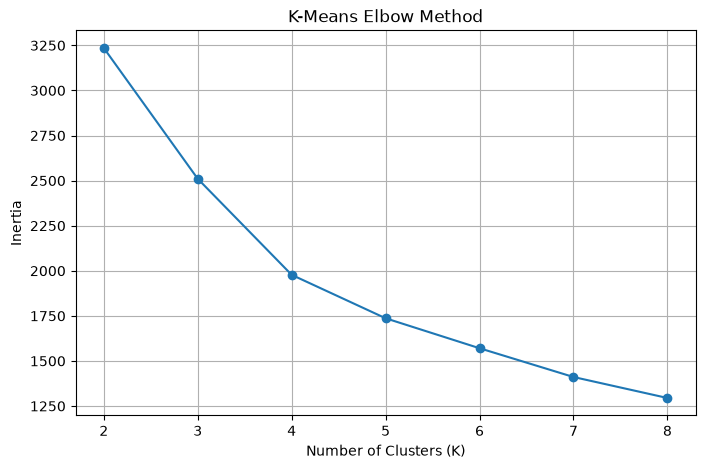

In [76]:
import matplotlib.pyplot as plt

k_values = range(2, 9)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(k_values)
plt.grid(True)
plt.show()

Create the silhouette plot

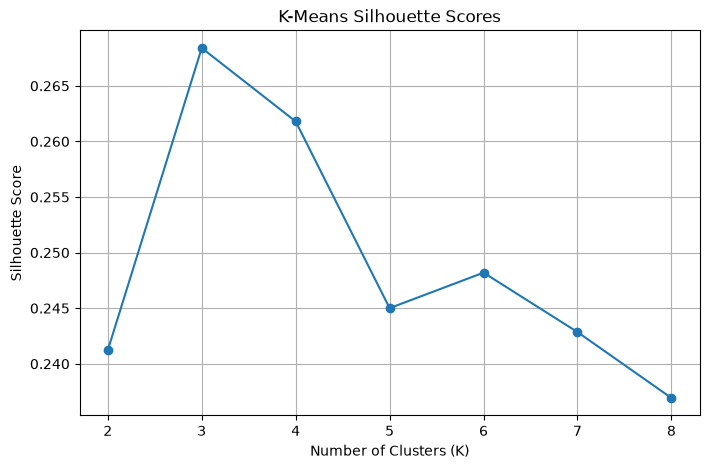

In [77]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")
plt.xticks(k_values)
plt.grid(True)
plt.show()

Create the final K-Means model

In [78]:
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["customer_segment"] = final_kmeans.fit_predict(cluster_scaled)

print(df["customer_segment"].value_counts().sort_index())

customer_segment
0    265
1    421
2    714
Name: count, dtype: int64


Describe the customer segments

In [79]:
segment_summary = df.groupby("customer_segment")[
    ["annual_income", "credit_score", "debt_to_income"]
].mean().round(2)

print(segment_summary)

                  annual_income  credit_score  debt_to_income
customer_segment                                             
0                     101667.51        703.85            0.22
1                      49204.52        682.19            0.40
2                      44975.61        674.56            0.16


Task 4 – Model Evaluation
Accuracy: How many predictions were correct overall?

Precision: Of the applicants predicted to default, how many actually defaulted?

Recall: Of all applicants who actually defaulted, how many did the model identify?

F1-score: A balance between precision and recall.



Calculate classification metrics

In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

classification_models = {
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

results = []

for name, predictions in classification_models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-Score": f1_score(y_val, predictions, zero_division=0)
    })

classification_results = pd.DataFrame(results)

print(classification_results.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.725      0.515   0.218     0.306
1        Decision Tree     0.750      0.583   0.359     0.444
2        Random Forest     0.729      0.550   0.141     0.224
3              XGBoost     0.736      0.611   0.141     0.229


Confusion Matrix

TN: Correctly predicted no default.

FP: Predicted default, but the customer did not default.

FN: Predicted no default, but the customer actually defaulted.

TP: Correctly predicted default.

Generate confusion matrices

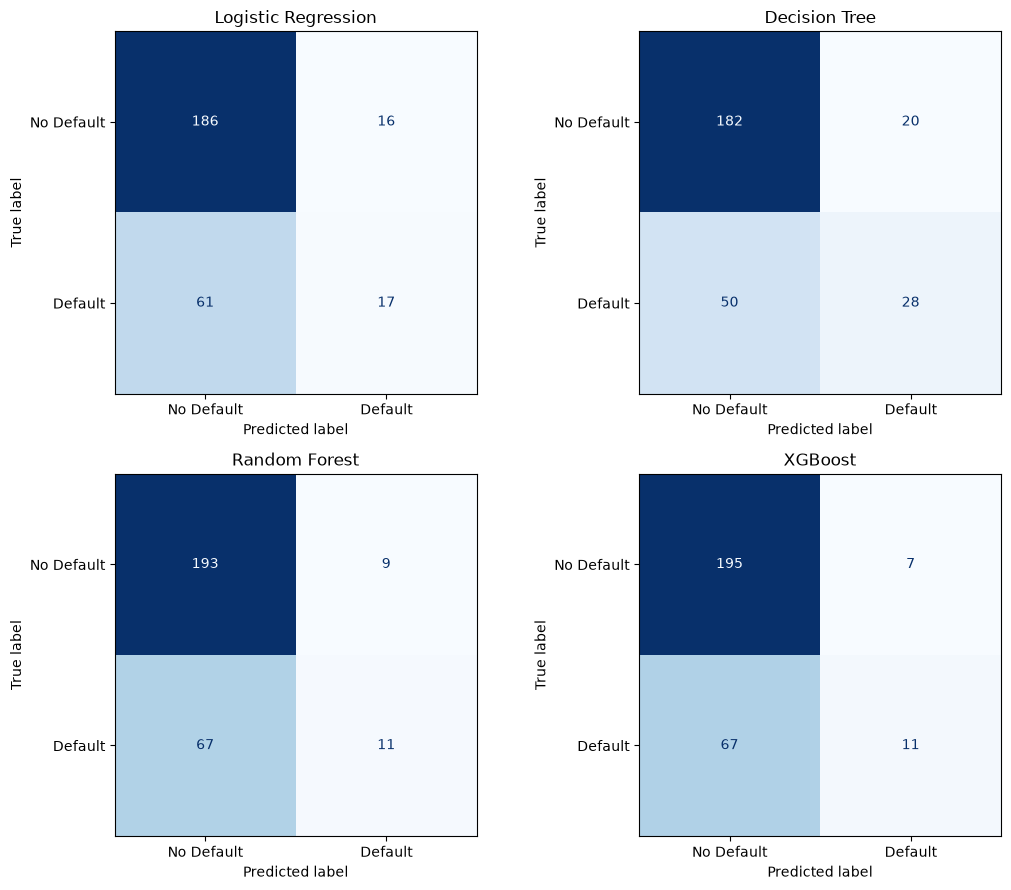

In [81]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for (name, predictions), ax in zip(
    classification_models.items(), axes.flatten()
):
    cm = confusion_matrix(y_val, predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Default", "Default"]
    )

    display.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

Understand class imbalance
Our dataset contains more customers who did not default than customers who did default.

In [82]:
print("Validation target distribution:")
print(y_val.value_counts())

print("\nValidation target percentages:")
print((y_val.value_counts(normalize=True) * 100).round(2))

Validation target distribution:
default
0    202
1     78
Name: count, dtype: int64

Validation target percentages:
default
0    72.14
1    27.86
Name: proportion, dtype: float64


ROC Curve and AUC

Calculate ROC curves for three models

use Logistic Regression, Decision Tree and XGBoost.

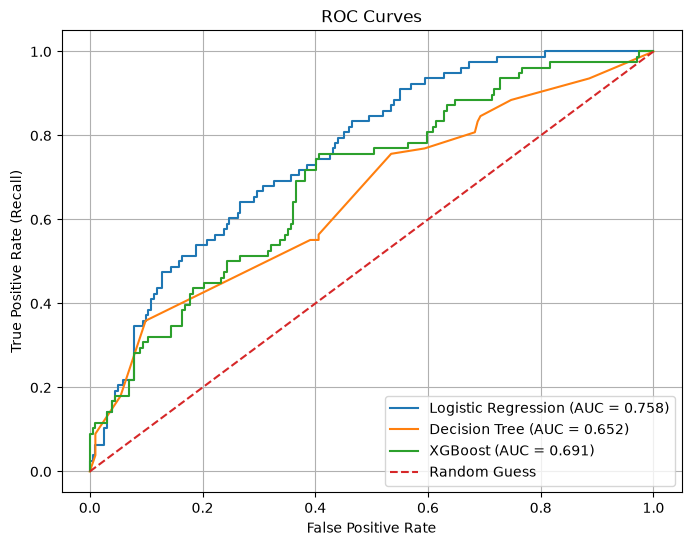

In [83]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

roc_models = {
    "Logistic Regression": lr_pipeline,
    "Decision Tree": dt_pipeline,
    "XGBoost": xgb_model
}

plt.figure(figsize=(8, 6))

for name, model in roc_models.items():

    if name == "XGBoost":
        probabilities = model.predict_proba(X_val_processed)[:, 1]
    else:
        probabilities = model.predict_proba(X_val)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_val, probabilities)

    auc_value = roc_auc_score(y_val, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

Calculate individual AUC values

In [84]:
for name, model in roc_models.items():

    if name == "XGBoost":
        probabilities = model.predict_proba(X_val_processed)[:, 1]
    else:
        probabilities = model.predict_proba(X_val)[:, 1]

    auc_value = roc_auc_score(y_val, probabilities)

    print(name, "AUC:", round(auc_value, 4))

Logistic Regression AUC: 0.758
Decision Tree AUC: 0.6516
XGBoost AUC: 0.6908


Choose a threshold that achieves at least 75% recall

In [85]:
import numpy as np
from sklearn.metrics import precision_recall_curve

roc_models = {
    "Logistic Regression": lr_pipeline,
    "Decision Tree": dt_pipeline,
    "XGBoost": xgb_model
}

for name, model in roc_models.items():

    if name == "XGBoost":
        probabilities = model.predict_proba(X_val_processed)[:, 1]
    else:
        probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    # Find thresholds that achieve at least 75% recall
    eligible = np.where(recall[:-1] >= 0.75)[0]

    if len(eligible) > 0:
        # Choose the eligible threshold with the highest precision
        best_idx = eligible[np.argmax(precision[eligible])]

        print(f"\n{name}")
        print("Threshold:", round(thresholds[best_idx], 4))
        print("Precision:", round(precision[best_idx], 4))
        print("Recall:", round(recall[best_idx], 4))
    else:
        print(f"\n{name}: No threshold achieved 75% recall.")


Logistic Regression
Threshold: 0.2301
Precision: 0.4106
Recall: 0.7949

Decision Tree
Threshold: 0.2328
Precision: 0.3533
Recall: 0.7564

XGBoost
Threshold: 0.2822
Precision: 0.4184
Recall: 0.7564


Hyperparameter tuning with GridSearchCV

In [86]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_search_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        oob_score=True,
        n_jobs=-1
    ))
])

# Settings to test
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=rf_search_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train and search
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)


Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross-Validation F1 Score:
0.1901733500417711


XGBoost hyperparameter tuning

In [87]:

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from xgboost import XGBClassifier

# Base XGBoost model
xgb_base = XGBClassifier(
    eval_metric="logloss",
    random_state=42
)

# Parameters to explore
param_distributions = {
    "n_estimators": randint(100, 501),
    "max_depth": randint(2, 7),
    "learning_rate": uniform(0.01, 0.19),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.7, 0.3)
}

# Randomized Search
xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=15,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

# Train using already processed training data
xgb_search.fit(X_train_processed, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(xgb_search.best_score_)


Best XGBoost Parameters:
{'colsample_bytree': np.float64(0.9579821220208962), 'learning_rate': np.float64(0.13925843233167814), 'max_depth': 2, 'n_estimators': 266, 'subsample': np.float64(0.7039794883479599)}

Best Cross-Validation F1 Score:
0.3643693919195671


Final evaluation on the test set

Evaluate tuned Random Forest

In [88]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

best_rf = grid_search.best_estimator_

rf_val_predictions = best_rf.predict(X_val)

print("Tuned Random Forest Validation Results")
print("Accuracy:", accuracy_score(y_val, rf_val_predictions))
print("Precision:", precision_score(y_val, rf_val_predictions))
print("Recall:", recall_score(y_val, rf_val_predictions))
print("F1 Score:", f1_score(y_val, rf_val_predictions))


Tuned Random Forest Validation Results
Accuracy: 0.7214285714285714
Precision: 0.5
Recall: 0.10256410256410256
F1 Score: 0.1702127659574468


Evaluate tuned XGBoost

In [89]:

best_xgb = xgb_search.best_estimator_

xgb_val_predictions = best_xgb.predict(X_val_processed)

print("Tuned XGBoost Validation Results")
print("Accuracy:", accuracy_score(y_val, xgb_val_predictions))
print("Precision:", precision_score(y_val, xgb_val_predictions))
print("Recall:", recall_score(y_val, xgb_val_predictions))
print("F1 Score:", f1_score(y_val, xgb_val_predictions))


Tuned XGBoost Validation Results
Accuracy: 0.6642857142857143
Precision: 0.34
Recall: 0.21794871794871795
F1 Score: 0.265625


Final test-set evaluation

In [90]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict on the untouched test set
X_test_processed = preprocessor.transform(X_test)

test_predictions = best_xgb.predict(X_test_processed)

# Final evaluation
print("FINAL TEST SET RESULTS")
print("-----------------------")

print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions))
print("Recall:", recall_score(y_test, test_predictions))
print("F1 Score:", f1_score(y_test, test_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))


FINAL TEST SET RESULTS
-----------------------
Accuracy: 0.7392857142857143
Precision: 0.5581395348837209
Recall: 0.3076923076923077
F1 Score: 0.39669421487603307

Confusion Matrix:
[[183  19]
 [ 54  24]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.91      0.83       202
           1       0.56      0.31      0.40        78

    accuracy                           0.74       280
   macro avg       0.67      0.61      0.62       280
weighted avg       0.71      0.74      0.71       280



Compare with a simple baseline

Regression results
Model	MAE	RMSE	R²
Mean Baseline	17,713.689	22,240.529	-0.002
Linear Regression	14,653.747	18,403.178	0.314
Ridge Regression	14,653.904	18,402.540	0.314
Lasso Regression	14,660.364	18,349.176	0.318

Interpretation
- MAE: Measures the average absolute difference between actual and predicted loan amounts.
- RMSE: Measures prediction error while penalising larger errors more heavily.
- R²: Measures how much variation in loan amount is explained by the model.
Conclusion:

Lasso Regression performed best overall based on RMSE and R². It achieved an RMSE of 18,349.176 and R² of 0.318.

All three regression models performed better than the mean baseline. However, the R² of 0.318 indicates that the models explain approximately 31.8% of the variation in loan amounts.
2. Final evaluation of the single best classification model
You selected the tuned XGBoost model based on its highest validation F1 score among the tuned models.
Final test evaluation completed
Final test results
Metric	Result
Accuracy	73.93%
Precision	55.81%
Recall	30.77%
F1 Score	39.67%

Confusion matrix
	Predicted 0	Predicted 1
Actual 0	183	19
Actual 1	54	24

Final report conclusion

Regression and Final Model Evaluation
Three regression models—Linear Regression, Ridge Regression and Lasso Regression—were evaluated against a mean baseline using MAE, RMSE and R².

Lasso Regression achieved the best RMSE of 18,349.176 and R² of 0.318, while Linear Regression achieved the lowest MAE of 14,653.747. All three regression models outperformed the mean baseline.

For classification, the tuned XGBoost model was selected based on its validation F1 score. It was evaluated once on the held-out test set and achieved 73.93% accuracy, 55.81% precision, 30.77% recall and an F1 score of 39.67%.

The results show that the model can identify some loan defaulters, but its recall needs improvement. The test set was kept separate from model training and hyperparameter tuning to provide an unbiased final evaluation.